In [1]:
#requirements
import pandas as pd
import numpy as np
import os, re, sys
import pickle

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import linear_kernel
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.preprocessing import MultiLabelBinarizer
from pathlib import Path


_cwd = Path.cwd()
PROJECT_ROOT = _cwd if (_cwd / "big_data").exists() else _cwd.parent
BIG_DATA   = PROJECT_ROOT / "big_data"
DATA_DIR   = PROJECT_ROOT / "data"
PLOTS_DIR  = PROJECT_ROOT / "plots"
PLOTS_DIR.mkdir(exist_ok=True)
print(f"PROJECT_ROOT: {PROJECT_ROOT}")


PROJECT_ROOT: c:\Users\<user>\bootcamps\CAPSTONE\Capstone1-text-prediction-for-scientific-papers


In [2]:
in_pkl = BIG_DATA / "baseline" / "pickle" / "clean_articles.pkl"
print(f"Input will be loaded from: {in_pkl}")
if not in_pkl.exists():
    print(f"Error: Input file {in_pkl} does not exist.")
    raise FileNotFoundError(f"Input file {in_pkl} does not exist.") 

Input will be loaded from: c:\Users\<user>\bootcamps\CAPSTONE\Capstone1-text-prediction-for-scientific-papers\big_data\baseline\pickle\clean_articles.pkl


In [3]:
keywords = set()

df = pd.read_pickle(in_pkl)
print(f"Data loaded successfully. Number of records: {len(df)}")
df.head(5)


Data loaded successfully. Number of records: 7702


,filename,pmcid,doi,journal,year,authors,title,keywords,abstract,introduction,methods,results,discussion,conclusion,tables,metadata_junk,kwd_lst,kwd_lst_cl,n_keywords,keywords_filtered
0,PMC1592647.xml,PMC1592647,10.1084/jem.20031051,The Journal of Experimental Medicine,2003,Berg Rance E.; Crossley Emily; Murray Sean; Fo...,Memory CD8 + T Cells Provide Innate Immune Pro...,IFN-γ; Listeria monocytogenes; T lymphocytes; ...,Interferon (IFN)-γ plays an important role in ...,The immune response against pathogenic microor...,"C57BL/6J (B6), C57BL/6.PL-Thy1 a /Cy (B6.Thy1....",We demonstrated previously that a population o...,CD8 + T cells play an important role in the co...,,[],,"[ifn-γ, listeria monocytogenes, t lymphocytes,...","[ifn, listeria monocytogenes, t lymphocytes, c...",5,[cytokines]
1,PMC1697748.xml,PMC1697748,10.1093/ecam/nel073,Evidence-based Complementary and Alternative M...,2006,Epstein O. I.; Pavlov I. F.; Shtark M. B.,Improvement of Memory by Means of Ultra-Low Do...,"Antigen S-100B; antibodies; ultra-low doses, m...","Antigen S-100B of nervous tissue, according to...",There is a constant interest in modern neuroph...,To prepare potentiated antibodies rabbit monos...,In the experiment on development of inhibitory...,The rats that were administered antibodies on ...,,[**Latencies of rats' descent from the platfor...,\n[unmapped: stimulation and registration of r...,"[antigen s-100b, antibodies, ultra-low doses, ...","[antigen s 100b, antibodies, ultra low doses, ...",4,[memory]
3,PMC1876602.xml,PMC1876602,10.1093/ecam/nel088,Evidence-based Complementary and Alternative M...,2007,Xia Rong; Huang Ping; Shao Guo-ming,Nourishing Yin and Promoting Blood Circulation...,Chinese material medica; diabetes mellitus rat...,"Diabetes mellitus, DM, is commonly accompanied...",Patients with diabetes mellitus (DM) usually d...,"Male Sprague-Dawley rats, about 3 months old, ...",The levels of FBG in the YYJT and experimental...,"In this study, we observed the effects of simp...","In this study, we showed that traditional medi...",[**Data in hemorheology after administration i...,,"[chinese material medica, diabetes mellitus ra...","[chinese material medica, diabetes mellitus ra...",8,"[insulin resistance, diabetes mellitus, growth..."
7,PMC2080686.xml,PMC2080686,10.1016/j.molimm.2007.06.162,Molecular Immunology,2008,Fossati-Jimack Liliane; Cortes-Hernandez Josef...,C1q deficiency promotes the production of tran...,"AEU, arbitrary ELISA units; Ab, antibody; Auto...",C1q-deficient mice have been shown to develop ...,Hereditary deficiencies of early components of...,"MRL/Mp mice were obtained from Harlan Olac, Bi...",C1q deficiency has been shown to accelerate th...,C1q deficiency in humans and in mice has been ...,,[**Splenic and peritoneum cell populations at ...,,"[autoimmunity, b cells, complement, rodent, tr...","[autoimmunity, b cells, complement, rodent, tr...",5,[b cells]
8,PMC2104744.xml,PMC2104744,10.3114/sim.2007.58.08,Studies in Mycology,2007,de Hoog G.S.; Nishikaku A.S.; Fernandez-Zeppen...,Molecular analysis and pathogenicity of the Cl...,Cactus; Cladophialophora; chromoblastomycosis;...,Cladophialophora carrionii is one of the four ...,"Cladophialophora carrionii (Trejos) de Hoog, K...",Strains studied are listed in C. carrionii . R...,The rDNA ITS region was sequenced for 43 strai...,"Judging from SSU rDNA phylogeny data, all Clad...",,[**Isolation data of Cladophialophora strains ...,,"[cactus, cladophialophora, chromoblastomycosis...","[cactus, cladophialophora, chromoblastomycosis...",7,[phylogeny]


In [4]:

print(f"Unique journals: {df['journal'].nunique()}")
print(df["journal"].unique())


Unique journals: 1958
['The Journal of Experimental Medicine'
 'Evidence-based Complementary and Alternative Medicine'
 'Evidence-based Complementary and Alternative Medicine : eCAM' ...
 'Journal of Veterinary Pharmacology and Therapeutics'
 'Npj 2d Materials and Applications' 'Cardiovascular Diabetology']


In [5]:

keywords = dict()
MIN_FREQ = 10

for index, row in df.iterrows():
        filename = row['filename']
        keywords_list = row['keywords'].lower().split(";")
        for keyword in keywords_list:
            keyword = keyword.strip()            
            if keywords.get(keyword) is None:
                keywords[keyword] = list()            
            keywords[keyword].append(filename)
sorted_keywords = {
    k: keywords[k] 
    for k in sorted(keywords, key=lambda x: len(keywords[x]), reverse=True)
    if len(keywords[k]) > MIN_FREQ 

}        
print(f"Filtered keywords (appearing in at least {MIN_FREQ} articles): {len(sorted_keywords)}")  


Filtered keywords (appearing in at least 10 articles): 460


In [6]:

# Global variable for workers (only inside the worker process)
worker_kw_sets = None

#if __name__ == '__main__':
# 1. Pre-convert to sets ONCE
in_pkl = BIG_DATA / "baseline" / "pickle" / "clean_articles.pkl"

print(f"Input will be loaded from: {in_pkl}")
if not in_pkl.exists():
    print(f"Error: Input file {in_pkl} does not exist.")
    raise FileNotFoundError(f"Input file {in_pkl} does not exist.") 

keywords_freq = set()

df = pd.read_pickle(in_pkl)
print(f"Data loaded successfully. Number of records: {len(df)}")
df.head(100)

print(f"Unique journals: {df['journal'].nunique()} are: {df['journal'].unique()}")    
print( f"Unique keywords: {df['keywords'].nunique()} are:  {df['keywords'].unique()}" )


# 2. Build the keyword frequency dictionary
# [keyword]->[list of filenames] (articles that contain this keyword)
keywords_freq = dict()
#
for index, row in df.iterrows():
    filename = row['filename']
    keywords_list = row['keywords'].lower().split(";")
    for keyword in keywords_list:
        keyword = keyword.strip()            
        if keywords_freq.get(keyword) is None:
            keywords_freq[keyword] = list()            
        keywords_freq[keyword].append(filename)
# Sort the dictionary ( C++ map ) by the length of the list of filenames (number of articles) in descending order
sorted_keywords = {
    k: keywords[k] 
    for k in sorted(keywords, key=lambda x: len(keywords[x]), reverse=True)
    if len(keywords[k]) > MIN_FREQ 
}  


Input will be loaded from: c:\Users\<user>\bootcamps\CAPSTONE\Capstone1-text-prediction-for-scientific-papers\big_data\baseline\pickle\clean_articles.pkl
Data loaded successfully. Number of records: 7702
Unique journals: 1958 are: ['The Journal of Experimental Medicine'
 'Evidence-based Complementary and Alternative Medicine'
 'Evidence-based Complementary and Alternative Medicine : eCAM' ...
 'Journal of Veterinary Pharmacology and Therapeutics'
 'Npj 2d Materials and Applications' 'Cardiovascular Diabetology']
Unique keywords: 7696 are:  <ArrowStringArray>
[                                                                                                                                      'IFN-γ; Listeria monocytogenes; T lymphocytes; cytokines; innate immunity',
                                                                                                                                                            'Antigen S-100B; antibodies; ultra-low doses, memory',
             

In [7]:
s_kwds= sorted_keywords.keys()
print(f"Filtered keywords (appearing in at least {MIN_FREQ} articles): {s_kwds}")  
for key in list(s_kwds)[:20]:
    print(f"Keyword: '{key}' appears in {keywords_freq[key]} articles.")

##############
# 1. Prepare data: list of 'filenames' for each 'keyword'
# We only care about keywords in sorted_keywords (the filtered ones)


Filtered keywords (appearing in at least 10 articles): dict_keys(['covid-19', 'prognosis', 'epidemiology', 'mortality', 'machine learning', 'risk factors', 'breast cancer', 'quality of life', 'apoptosis', 'depression', 'obesity', 'inflammation', 'cancer', 'public health', 'children', 'meta-analysis', 'stroke', 'survival', 'hypertension', 'biomarker', 'dementia', 'anxiety', 'immunotherapy', 'biomarkers', 'hepatocellular carcinoma', 'heart failure', 'sars-cov-2', 'oxidative stress', 'colorectal cancer', 'mental health', 'diagnosis', 'prevalence', 'diabetes mellitus', 'qualitative research', 'diabetes', 'magnetic resonance imaging', 'pregnancy', 'autophagy', 'physical activity', 'deep learning', 'lung cancer', 'type 2 diabetes', 'gastric cancer', 'chemotherapy', 'prostate cancer', 'schizophrenia', 'osteoporosis', "alzheimer's disease", 'metastasis', 'asthma', 'chronic kidney disease', 'primary care', 'hiv', 'atrial fibrillation', 'radiotherapy', 'surgery', 'aging', 'elderly', 'stress', 'a

In [8]:

data_for_matrix = [keywords_freq[kw] for kw in sorted_keywords]


In [9]:
# 2. Vectorize: Convert lists of filenames into a Binary Sparse Matrix
# MultiLabelBinarizer creates a matrix where rows=keywords, cols=unique_filenames
mlb = MultiLabelBinarizer(sparse_output=True)
matrix = mlb.fit_transform(data_for_matrix)

print(f"Matrix shape: {matrix.shape}") # (num_keywords, num_unique_articles)

# 3. Compute Co-occurrence: A * A^T
# adj_full[i,j] = number of articles containing both keyword i and keyword j
adj_full = matrix.dot(matrix.T)  # symmetric sparse matrix

# 4. Dense + log-transform for clustering and visualization
adj_dense = adj_full.toarray().astype(float)
adj_log = np.log1p(adj_dense)  # log(1+x): 0 stays 0, compresses large values

# 5. Sparsity report
total = adj_dense.size
nonzero = np.count_nonzero(adj_dense)
print(f"Sparsity: {1 - nonzero/total:.1%} ({nonzero} non-zero of {total})")
print(f"Max co-occurrence: {int(adj_dense.max())}")
print(f"After log1p — max: {adj_log.max():.2f}, mean (non-zero): {adj_log[adj_log>0].mean():.2f}")

# 6. Extract top pairs (upper triangle only, to avoid duplicates)
from scipy import sparse as sp
adj_triu = sp.triu(adj_full, k=1).tocoo()

# sorted_keywords is a dict with string keys — use a list for integer indexing
kw_list = list(sorted_keywords.keys())

results = []
for i, j, val in zip(adj_triu.row, adj_triu.col, adj_triu.data):
    results.append(((kw_list[i], kw_list[j]), val))

# 7. Sort and print top 10
sorted_kw_intersections = sorted(results, key=lambda x: x[1], reverse=True)
for pair, length in sorted_kw_intersections[:10]:
    print(f"Pair: {pair}, Intersection: {length}")

Matrix shape: (460, 6425)
Sparsity: 94.9% (10874 non-zero of 211600)
Max co-occurrence: 244
After log1p — max: 5.50, mean (non-zero): 0.92
Pair: ('covid-19', 'sars-cov-2'), Intersection: 44
Pair: ('depression', 'anxiety'), Intersection: 34
Pair: ('epidemiology', 'public health'), Intersection: 25
Pair: ('meta-analysis', 'systematic review'), Intersection: 15
Pair: ('health care', 'medical research'), Intersection: 15
Pair: ('obesity', 'body mass index'), Intersection: 12
Pair: ('safety', 'efficacy'), Intersection: 12
Pair: ('molecular biology', 'cell biology'), Intersection: 12
Pair: ('proliferation', 'migration'), Intersection: 12
Pair: ('covid-19', 'public health'), Intersection: 11


In [10]:
from sklearn.cluster import SpectralClustering

# SpectralClustering requires a symmetric non-negative affinity matrix
# adj_log is symmetric and non-negative -> ready to use
sc = SpectralClustering(n_clusters=10, affinity="precomputed", random_state=42)
labels = sc.fit_predict(adj_log)

# Map keywords to clusters
clusters = {}
for idx, label in enumerate(labels):
    kw = kw_list[idx]  # use list for integer indexing
    clusters.setdefault(label, []).append(kw)

# Print clusters
for cluster_id in sorted(clusters.keys()):
    print(f"Cluster {cluster_id}: {clusters[cluster_id][:10]}")

Cluster 0: ['apoptosis', 'oxidative stress', 'autophagy', 'proliferation', 'migration', 'osteoarthritis', 'angiogenesis', 'ferroptosis', 'gene expression', 'invasion']
Cluster 1: ['reliability', 'validity', 'analgesia', 'knee', 'total knee arthroplasty', 'hip', 'biomechanics', 'arthroplasty', 'total hip arthroplasty', 'complication']
Cluster 2: ['epidemiology', 'mortality', 'risk factors', 'obesity', 'inflammation', 'children', 'meta-analysis', 'stroke', 'hypertension', 'heart failure']
Cluster 3: ['quality of life', 'depression', 'public health', 'dementia', 'anxiety', 'mental health', 'prevalence', 'qualitative research', 'physical activity', 'schizophrenia']
Cluster 4: ['antibiotics', 'bacteria', 'escherichia coli', 'staphylococcus aureus', 'antimicrobial resistance', 'genotype', 'atopic dermatitis', 'biofilm']
Cluster 5: ['in vitro', 'antibiotic resistance', 'salmonella', 'e. coli']
Cluster 6: ['prognosis', 'machine learning', 'breast cancer', 'cancer', 'survival', 'biomarker', 'im

In [11]:
import seaborn as sns
import scipy
from matplotlib import pyplot as plt

# Use log-transformed matrix for visualization (same as clustering)
df_adj = pd.DataFrame(adj_log, index=sorted_keywords, columns=sorted_keywords)

# Show only top N keywords for readability
TOP_N = 50
df_adj_top = df_adj.iloc[:TOP_N, :TOP_N]


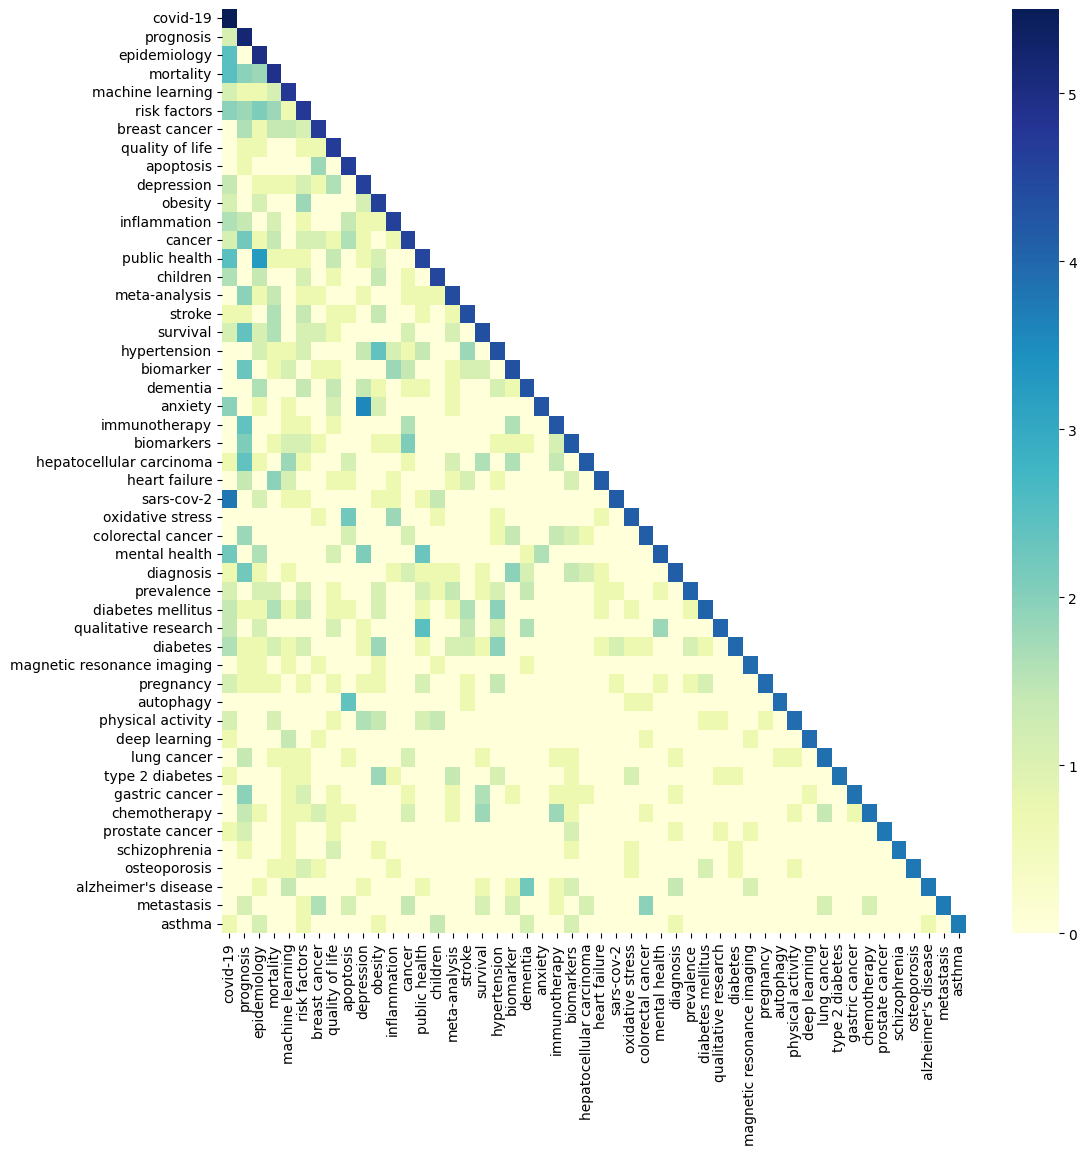

In [12]:
fig, ax = plt.subplots(figsize=(12, 12))
mask = np.triu(np.ones_like(df_adj_top, dtype=bool), k=1)
sns.heatmap(df_adj_top, cmap="YlGnBu", mask=mask,
            xticklabels=True, yticklabels=True, ax=ax)
plt.savefig(PLOTS_DIR / "keyword_cooccurrence_heatmap.png", dpi=120, bbox_inches="tight")
plt.show()

C:\Users\<user>\AppData\Local\Temp\ipykernel_9984\2401151602.py:14: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  color_map = plt.cm.get_cmap("tab20", len(components))


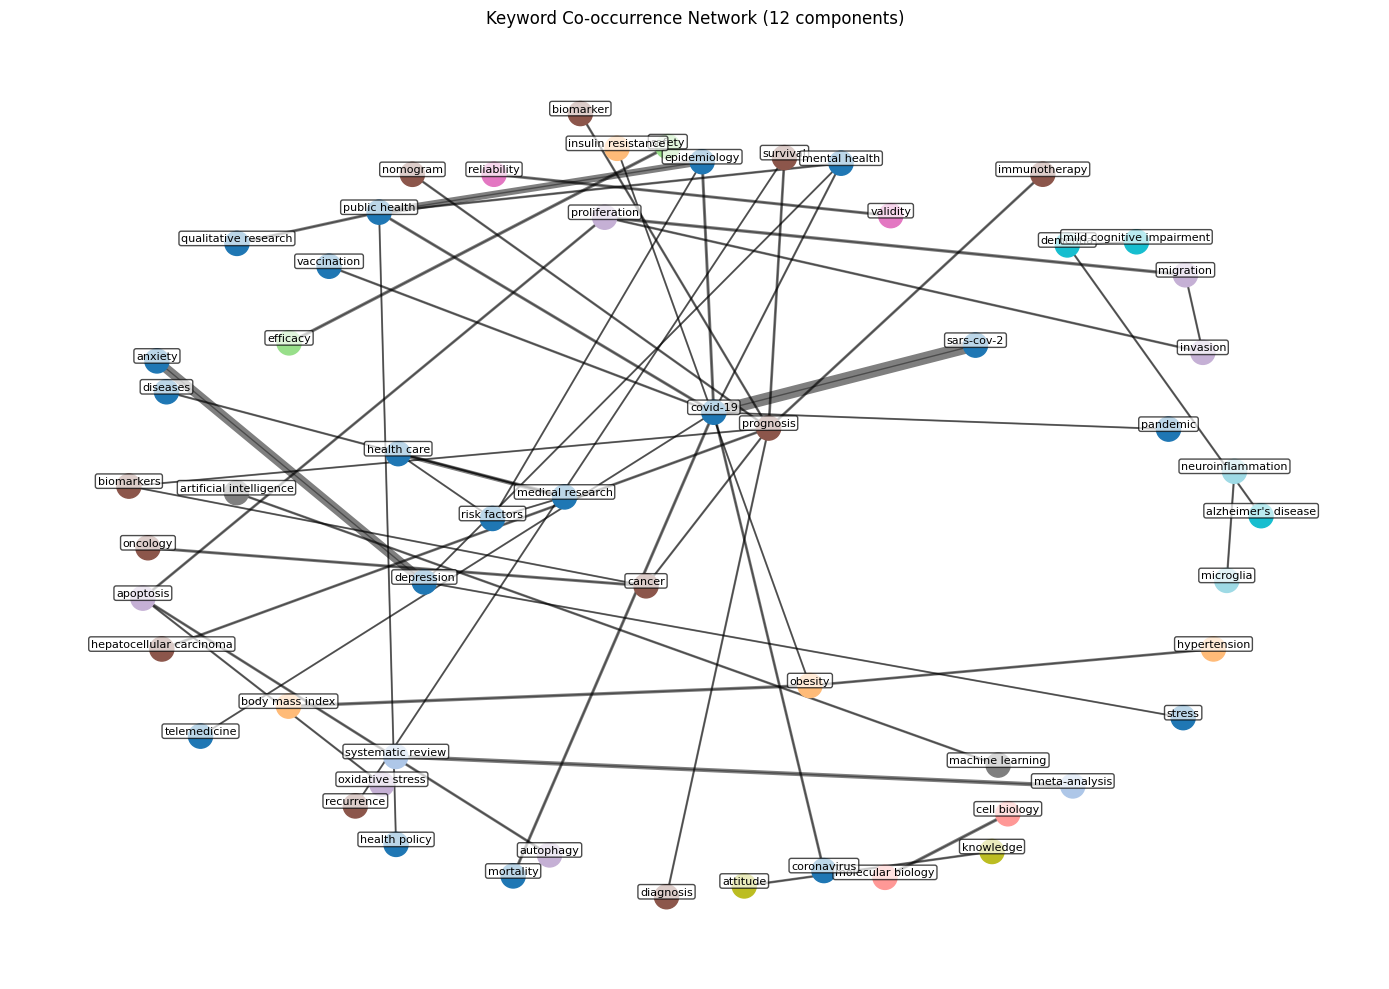

In [13]:
#!pip install networkx
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import numpy as np

G = nx.Graph()
for (kw1, kw2), val in sorted_kw_intersections[:50]:
    if val >= 3:
        G.add_edge(kw1, kw2, weight=val)

# Connected components als Cluster → jede Komponente bekommt eigene Farbe
components = list(nx.connected_components(G))
color_map = plt.cm.get_cmap("tab20", len(components))

node_colors = {}
for i, component in enumerate(components):
    for node in component:
        node_colors[node] = color_map(i)

colors = [node_colors[n] for n in G.nodes()]

fig, ax = plt.subplots(figsize=(14, 10))
pos = nx.spring_layout(G, seed=42, k=2.5,
                       weight="weight")  # Gewicht beeinflusst Abstände


weights = [G[u][v]["weight"] for u, v in G.edges()]
nx.draw_networkx_edges(G, pos, width=[w*0.2 for w in weights], alpha=0.5, ax=ax)

nx.draw_networkx_nodes(G, pos, node_size=300, node_color=colors, ax=ax)
nx.draw_networkx_edges(G, pos, alpha=0.4, ax=ax)
nx.draw_networkx_labels(G, pos, font_size=8,
                        verticalalignment="bottom",
                        bbox=dict(boxstyle="round,pad=0.2", fc="white", alpha=0.7),
                        ax=ax)

ax.set_title(f"Keyword Co-occurrence Network ({len(components)} components)", fontsize=12)
ax.axis("off")
plt.tight_layout()
plt.savefig(PLOTS_DIR / "keyword_network.png", dpi=150, bbox_inches="tight")
plt.show()